# Inferences About the Slope
---

## Experiment: calculate a slope test and interval manually.

In [1]:
import numpy as np
from scipy import stats

x = np.arange(1., 10.)
y = np.array([2.2, 2.3, 3.7, 4.1, 5.0, 5.7, 6.4, 7.4, 7.8])
n = x.size
s_xx = np.sum((x - x.mean()) ** 2)
b1 = np.sum((x - x.mean()) * (y - y.mean())) / s_xx
b0 = y.mean() - b1 * x.mean()
residual = y - (b0 + b1 * x)
s = np.sqrt(np.sum(residual**2) / (n - 2))
se = s / np.sqrt(s_xx)
t_obs = b1 / se
p = 2 * stats.t.sf(abs(t_obs), df=n - 2)
t_star = stats.t.ppf(0.975, df=n - 2)
ci = (b1 - t_star * se, b1 + t_star * se)

print(f"Slope={b1:.5f}, SE={se:.5f}, t={t_obs:.5f}, p={p:.6g}")
print("95% CI:", tuple(round(v, 5) for v in ci))
print("SciPy linregress:", stats.linregress(x, y))

Slope=0.74500, SE=0.02931, t=25.42111, p=3.72268e-08
95% CI: (0.6757, 0.8143)
SciPy linregress: LinregressResult(slope=0.7450000000000001, intercept=1.2305555555555543, rvalue=0.9946276006138306, pvalue=3.722678098537372e-08, stderr=0.029306354837516223, intercept_stderr=0.16491607079251858)


## Experiment: compare SciPy and statsmodels on a height–weight sample.

In [2]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.stats import linregress

url = "https://userpage.fu-berlin.de/soga/data/raw-data/students.csv"
students = pd.read_csv(url)
if len(students) < 12:
    raise ValueError("Fewer than 12 students in the source dataset")
sample = students.sample(n=12, random_state=9)[["height", "weight"]]
sample = sample.apply(pd.to_numeric, errors="coerce").dropna()
if len(sample) < 3:
    raise ValueError("Not enough complete pairs after the original 12-row sampling")
x = sample["height"].to_numpy()
y = sample["weight"].to_numpy()
fit = sm.OLS(y, sm.add_constant(x)).fit()
scipy_fit = linregress(x, y)

print("Sample n:", len(sample))
print("Slope and estimated standard error:", fit.params[1], fit.bse[1])
print("Two-sided slope p-value:", fit.pvalues[1])
print("95% slope CI:", fit.conf_int(alpha=0.05)[1])
print("SciPy slope / p-value:", scipy_fit.slope, scipy_fit.pvalue)
print("Coefficients agree:", np.isclose(fit.params[1], scipy_fit.slope))

Sample n: 12
Slope and estimated standard error: 0.7477660695468905 0.08561453550613
Two-sided slope p-value: 5.414310239986698e-06
95% slope CI: [0.557005   0.93852714]
SciPy slope / p-value: 0.7477660695468913 5.414310239986678e-06
Coefficients agree: True


## Experiment: simulate exact slope t-inference under normal errors.

95% CI coverage=0.9530; null rejection=0.0470


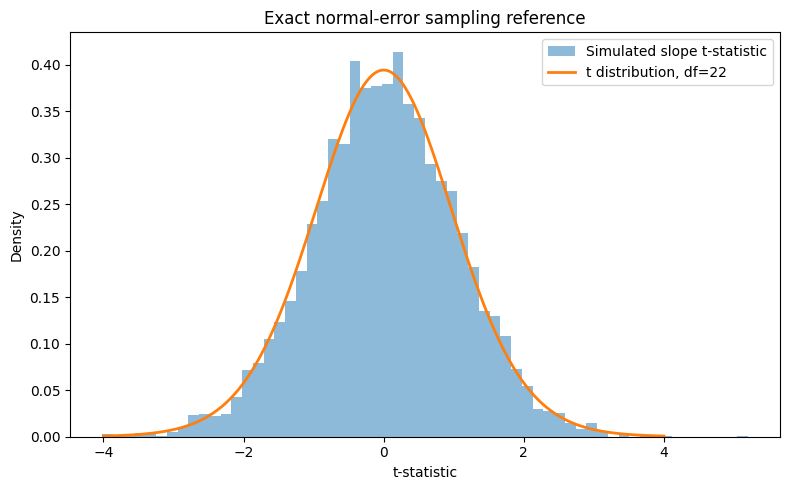

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(115)
B, n, true_slope = 5000, 24, 0.0
x = np.linspace(-2, 2, n)
xc = x - x.mean()
s_xx = np.sum(xc**2)
errors = rng.normal(size=(B, n))
b1 = true_slope + errors @ xc / s_xx
b0_error = errors.mean(axis=1)
residuals = errors - b0_error[:, None] - (b1 - true_slope)[:, None] * xc
s = np.sqrt(np.sum(residuals**2, axis=1) / (n - 2))
se = s / np.sqrt(s_xx)
t_values = (b1 - true_slope) / se
critical = stats.t.ppf(0.975, n - 2)
coverage = np.mean(np.abs(t_values) <= critical)
rejection = np.mean(np.abs(t_values) > critical)
print(f"95% CI coverage={coverage:.4f}; null rejection={rejection:.4f}")

z = np.linspace(-4, 4, 400)
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(t_values, bins=60, density=True, alpha=0.5, label="Simulated slope t-statistic")
ax.plot(z, stats.t.pdf(z, n - 2), linewidth=2, label=f"t distribution, df={n-2}")
ax.set(xlabel="t-statistic", ylabel="Density", title="Exact normal-error sampling reference")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/slope_t_reference.png", dpi=170, bbox_inches="tight")
plt.show()

## Experiment: compare conventional and HC3 tests under heteroskedasticity.

Null rejection rates (nominal 5%): {'Classical': 0.083, 'HC3': 0.061}


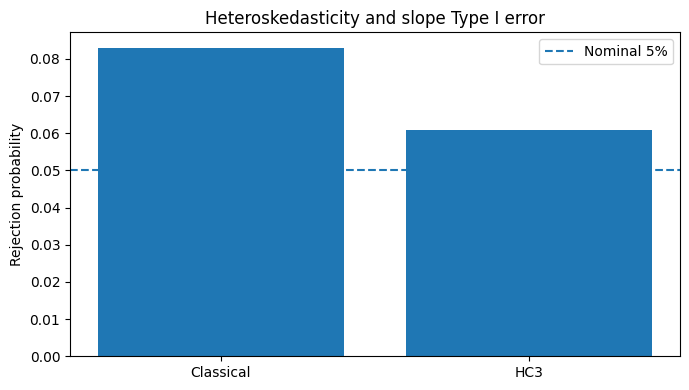

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

rng = np.random.default_rng(116)
B, n = 1000, 80
x = np.linspace(0, 1, n)
X = sm.add_constant(x)
spread = 0.2 + 3.0 * x  # True slope is zero; variance grows with x
count_classical = 0
count_hc3 = 0
for _ in range(B):
    y = rng.normal(0, spread)
    fit = sm.OLS(y, X).fit()
    count_classical += fit.pvalues[1] < 0.05
    count_hc3 += fit.get_robustcov_results(cov_type="HC3").pvalues[1] < 0.05
rates = [count_classical / B, count_hc3 / B]
print("Null rejection rates (nominal 5%):", dict(zip(["Classical", "HC3"], rates)))

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(["Classical", "HC3"], rates)
ax.axhline(0.05, linestyle="--", label="Nominal 5%")
ax.set(ylabel="Rejection probability", title="Heteroskedasticity and slope Type I error")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/slope_heteroskedastic_type1.png", dpi=170, bbox_inches="tight")
plt.show()

## Experiment: contrast statistical and practical importance.

In [5]:
import numpy as np
from scipy.stats import linregress, t

rng = np.random.default_rng(117)
true_slope = 0.09  # 0.9 response units across the entire x-range [0, 10]
for n in [30, 2500]:
    x = rng.uniform(0, 10, n)
    y = 5 + true_slope * x + rng.normal(0, 3, n)
    result = linregress(x, y)
    half_width = t.ppf(0.975, n - 2) * result.stderr
    print(f"n={n}: slope={result.slope:.4f}, p={result.pvalue:.5g}, "
          f"95% CI=({result.slope-half_width:.4f}, {result.slope+half_width:.4f}), "
          f"R2={result.rvalue**2:.4f}")
print("Even a significant slope can account for little of the response variation.")

n=30: slope=0.2972, p=0.096539, 95% CI=(-0.0568, 0.6512), R2=0.0955
n=2500: slope=0.0848, p=2.6585e-05, 95% CI=(0.0453, 0.1243), R2=0.0070
Even a significant slope can account for little of the response variation.
